# Customer Spending Prediction using Pipeline and ColumnTransformer
### E-Commerce Machine Learning Project for ShopSmart



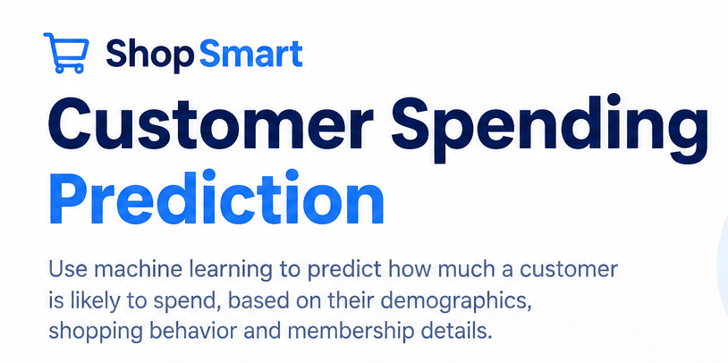

## 1. Import Libraries


In [175]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



# Load the Data


In [145]:
# Load the dataset
df = pd.read_csv(r'D:\Customer Spending Prediction\dataset\ShopSmart_Customer_Spending_Dataset_v2.csv')
print(f'Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns')
print('\nFirst 5 records:')
df.head()

Dataset Shape: 2000 rows, 9 columns

First 5 records:


,Age,Annual_Income,Website_Visits,Previous_Purchases,Membership_Type,Preferred_Category,City_Tier,Discount_Used,Amount_Spent
0,46,620358.0,11.0,8,Silver,Beauty,Tier 1,Yes,16924.36
1,27,560886.0,13.0,7,Silver,Fashion,Tier 1,No,16467.52
2,52,866655.0,11.0,9,Bronze,Home,Tier 1,No,19224.61
3,55,816016.0,17.0,9,Silver,Home,Tier 2,Yes,20219.63
4,18,355468.0,14.0,0,Bronze,Home,Tier 3,Yes,7345.37


In [146]:
# Dataset summary information
print('--- Dataset Info ---')
df.info()

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 2000 non-null   int64  
 1   Annual_Income       1984 non-null   float64
 2   Website_Visits      1984 non-null   float64
 3   Previous_Purchases  2000 non-null   int64  
 4   Membership_Type     1984 non-null   str    
 5   Preferred_Category  1984 non-null   str    
 6   City_Tier           2000 non-null   str    
 7   Discount_Used       2000 non-null   str    
 8   Amount_Spent        2000 non-null   float64
dtypes: float64(3), int64(2), str(4)
memory usage: 182.7 KB


In [147]:
# Summary statistics for numerical variables
print('--- Summary Statistics ---')
df.describe()

--- Summary Statistics ---


,Age,Annual_Income,Website_Visits,Previous_Purchases,Amount_Spent
count,2000.000000,1.984000e+03,1984.000000,2000.0000,2000.000000
mean,40.917500,7.525418e+05,9.956149,6.9655,17505.982405
std,12.780116,2.739564e+05,3.103784,2.6235,3866.061235
min,18.000000,1.800000e+05,2.000000,0.0000,6875.410000
25%,32.000000,5.596122e+05,8.000000,5.0000,14864.417500
50%,41.000000,7.499965e+05,10.000000,7.0000,17381.955000
75%,50.000000,9.372420e+05,12.000000,9.0000,19927.317500
max,65.000000,1.604606e+06,20.000000,16.0000,35371.200000


In [148]:
# Missing values and duplicate checks
print('--- Missing Values Check ---')
print(df.isnull().sum())

duplicates = df.duplicated().sum()
print(f'\nTotal Duplicate Records: {duplicates}')

--- Missing Values Check ---
Age                    0
Annual_Income         16
Website_Visits        16
Previous_Purchases     0
Membership_Type       16
Preferred_Category    16
City_Tier              0
Discount_Used          0
Amount_Spent           0
dtype: int64

Total Duplicate Records: 0


In [149]:
df['Membership_Type'].value_counts()

Membership_Type
Bronze    876
Silver    743
Gold      365
Name: count, dtype: int64

In [150]:
df['Preferred_Category'].value_counts()

Preferred_Category
Fashion        588
Electronics    555
Home           483
Beauty         358
Name: count, dtype: int64

In [151]:
df['City_Tier'].value_counts()

City_Tier
Tier 2    739
Tier 1    714
Tier 3    547
Name: count, dtype: int64

In [152]:
# Fill numerical columns with their column means
for column in ["Annual_Income", "Website_Visits"]:
    df[column] = df[column].fillna(df[column].mean())

# Fill categorical columns with their most frequent values
for column in ["Membership_Type", "Preferred_Category"]:
    df[column] = df[column].fillna(df[column].mode()[0])

print("Remaining missing values:", df.isna().sum().sum())

Remaining missing values: 0


In [153]:
df.shape

(2000, 9)

In [154]:
#observing numeric columns
num_cols = []
for col in df.columns:
  if df[col].dtype!='str':
    num_cols.append(col)
df[num_cols]

,Age,Annual_Income,Website_Visits,Previous_Purchases,Amount_Spent
0,46,620358.0,11.0,8,16924.36
1,27,560886.0,13.0,7,16467.52
2,52,866655.0,11.0,9,19224.61
3,55,816016.0,17.0,9,20219.63
4,18,355468.0,14.0,0,7345.37
...,...,...,...,...,...
1995,47,557297.0,5.0,6,17423.64
1996,46,1027242.0,11.0,12,19939.64
1997,40,677690.0,15.0,4,13397.79
1998,34,565410.0,11.0,8,17682.11


In [155]:
#observing object data
for col in df.select_dtypes(include=['object', 'string']).columns:
    print(col, "--->", list(df[col].unique()))

Membership_Type ---> ['Silver', 'Bronze', 'Gold']
Preferred_Category ---> ['Beauty', 'Fashion', 'Home', 'Electronics']
City_Tier ---> ['Tier 1', 'Tier 2', 'Tier 3']
Discount_Used ---> ['Yes', 'No']


### Exploratory Data Analysis (EDA)


Text(0.5, 1.0, 'Distribution of Amount Spent')

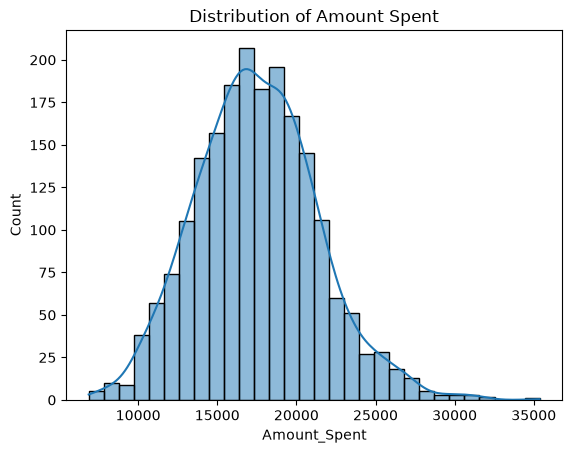

In [156]:
# Exploratory Data Analysis Visualizations


# 1. Target Distribution
sns.histplot(data=df, x='Amount_Spent', bins=30, kde=True)
plt.title('Distribution of Amount Spent')

Text(0.5, 1.0, 'Annual Income vs Amount Spent')

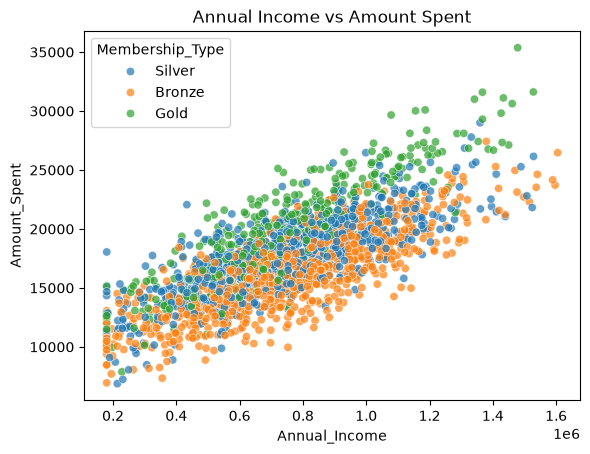

In [157]:

# 2. Annual Income vs Amount Spent
sns.scatterplot(data=df, x='Annual_Income', y='Amount_Spent', hue='Membership_Type', alpha=0.7)
plt.title('Annual Income vs Amount Spent')

<Axes: xlabel='Membership_Type', ylabel='Amount_Spent'>

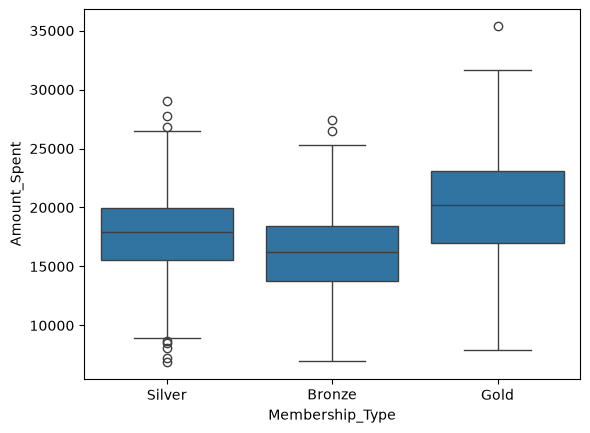

In [158]:
sns.boxplot(data=df, x='Membership_Type', y='Amount_Spent')

In [159]:
corr=df[num_cols].corr()
corr

,Age,Annual_Income,Website_Visits,Previous_Purchases,Amount_Spent
Age,1.000000,0.009783,-0.005477,0.010538,0.146029
Annual_Income,0.009783,1.000000,0.041155,0.048352,0.752104
Website_Visits,-0.005477,0.041155,1.000000,0.011144,0.133869
Previous_Purchases,0.010538,0.048352,0.011144,1.000000,0.389283
Amount_Spent,0.146029,0.752104,0.133869,0.389283,1.000000


<Axes: >

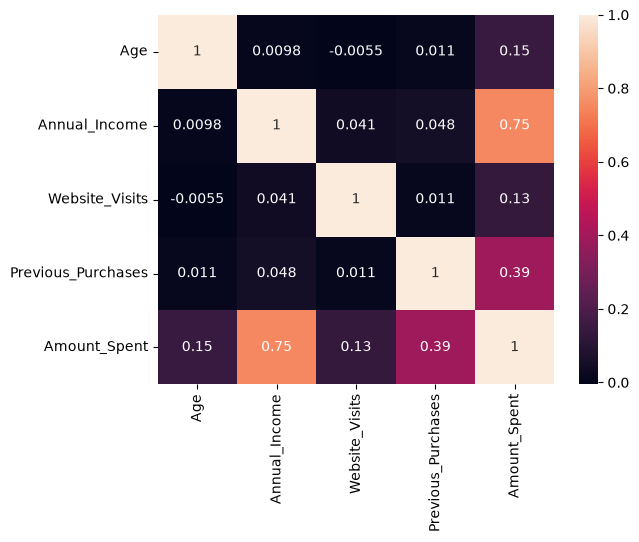

In [160]:
sns.heatmap(corr, annot=True)

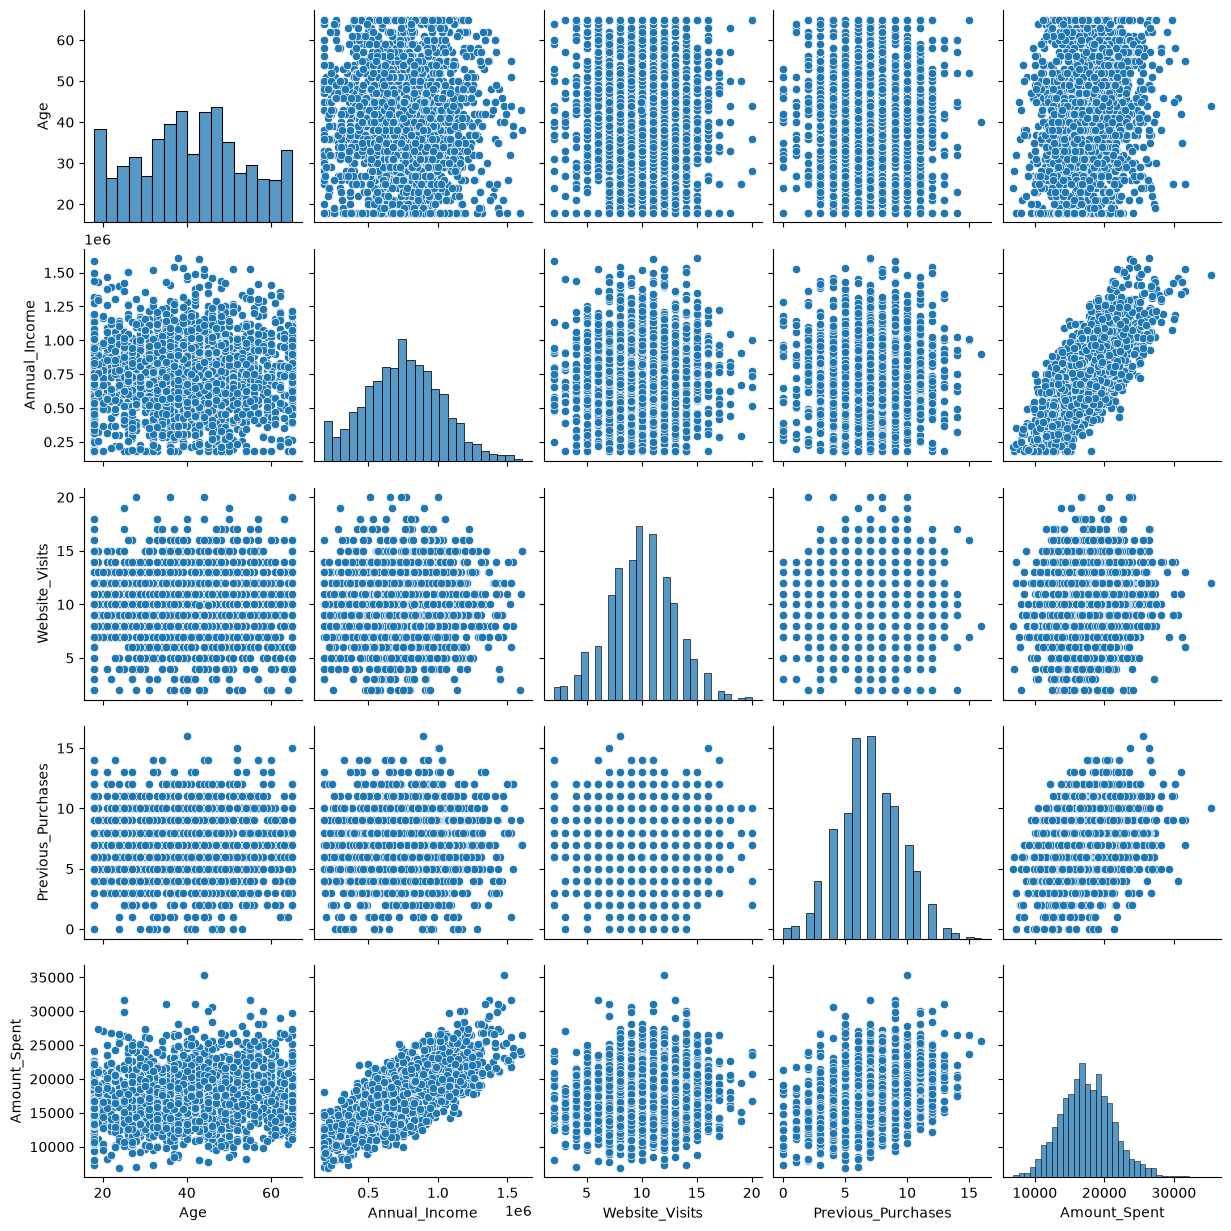

In [161]:
sns.pairplot(df)

# Prepare Features and Target


In [162]:
# Separate target variable and feature set
x = df.drop(columns=['Amount_Spent'])
y = df['Amount_Spent']

# Split data into train and test (80/20 split)
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=42
)

print(f'x_train Shape: {x_train.shape}')
print(f'x_test  Shape: {x_test.shape}')
print(f'y_train Shape: {y_train.shape}')
print(f'y_test  Shape: {y_test.shape}')

x_train Shape: (1400, 8)
x_test  Shape: (600, 8)
y_train Shape: (1400,)
y_test  Shape: (600,)


# Build Preprocessing with ColumnTransformer


In [163]:
# Define numerical and categorical columns
num_cols = ['Age', 'Annual_Income', 'Website_Visits', 'Previous_Purchases']
cat_cols = ['Membership_Type', 'Preferred_Category', 'City_Tier', 'Discount_Used']


# Combine using ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
                    ("encoder",OneHotEncoder(),cat_cols),
                    ("scaler",StandardScaler(),num_cols)
])

print('Preprocessor definition:')
print(preprocessor)

Preprocessor definition:
ColumnTransformer(transformers=[('encoder', OneHotEncoder(),
                                 ['Membership_Type', 'Preferred_Category',
                                  'City_Tier', 'Discount_Used']),
                                ('scaler', StandardScaler(),
                                 ['Age', 'Annual_Income', 'Website_Visits',
                                  'Previous_Purchases'])])


# Train Multiple Models Using Pipeline


In [185]:
# Define regression models
models={
    "lr": Pipeline([("preprocessor", ColumnTransformer([
                    ("encoder",OneHotEncoder(),cat_cols),
                    ("scaler",StandardScaler(),num_cols)])),
                    ('model',LinearRegression())]),
    "ridge": Pipeline([("preprocessor", ColumnTransformer([
                    ("encoder",OneHotEncoder(),cat_cols),
                    ("scaler",StandardScaler(),num_cols)])),
                    ('model',Ridge(alpha=50))]),
    "lasso": Pipeline([("preprocessor", ColumnTransformer([
                    ("encoder",OneHotEncoder(),cat_cols),
                    ("scaler",StandardScaler(),num_cols)])),
                    ('model',Lasso(alpha=100))]),
    "dt": Pipeline([("preprocessor", ColumnTransformer([
                        ("encoder",OneHotEncoder(),cat_cols),
                        ("scaler",StandardScaler(),num_cols)])),
                        ('model',DecisionTreeRegressor(max_depth=10))]),                
    "rf": Pipeline([("preprocessor", ColumnTransformer([
                    ("encoder",OneHotEncoder(),cat_cols),
                    ("scaler",StandardScaler(),num_cols)])),
                    ('model',RandomForestRegressor(n_estimators=100,max_depth=7, random_state=42))])
}
model_perf = {}
for model_name,pipeline in models.items():
  pipeline.fit(x_train,y_train)
  y_pred = pipeline.predict(x_test)
  r2=r2_score(y_test,y_pred)
  mae=mean_absolute_error(y_test,y_pred)
  mse=mean_squared_error(y_test,y_pred)

  model_perf[model_name]={ "R2": r2, "MAE": mae, "MSE": mse}

In [186]:
perf=pd.DataFrame(model_perf).T
perf

,R2,MAE,MSE
lr,0.948411,617.579872,7.487812e+05
ridge,0.945508,637.828947,7.909113e+05
lasso,0.921938,821.415694,1.133022e+06
dt,0.778570,1398.801949,3.213899e+06
rf,0.855759,1133.306983,2.093566e+06


In [199]:
# fetching the best pipeline
best_model_data = max(model_perf.items(),key=lambda x:x[1]['R2'])
best_model_name = best_model_data[0]
best_model = models[best_model_name]
print(f'Best Model: {best_model_name} with R2 Score: {best_model_data[1]["R2"]}')

Best Model: lr with R2 Score: 0.9484108461662709


In [ ]:
best_model.predict(x_test)

# Predict Spending for a New Customer



In [200]:
new_data =  x_test.sample()
new_data

,Age,Annual_Income,Website_Visits,Previous_Purchases,Membership_Type,Preferred_Category,City_Tier,Discount_Used
712,27,725214.0,13.0,7,Gold,Fashion,Tier 2,No


In [201]:
pred = best_model.predict(new_data)[0]
print(f"Predicted spending for the new customer: {pred:.2f}")

Predicted spending for the new customer: 18772.11


In [202]:
# save the best model (serialization)
import pickle
with open(r"D:\Customer Spending Prediction\best_model\best_model_pipeline.pkl", "wb") as file:
    pickle.dump(best_model, file)
    print("Best model saved successfully.")

Best model saved successfully.


In [203]:
df.to_csv(r'D:\Customer Spending Prediction\dataset\cleaned_spending_data.csv')

In [204]:
# save the dataframe into datasets
perf.to_csv(r"D:\Customer Spending Prediction\dataset\model_performance.csv")